# Forward and reverse diffusion on a real photograph

Booster LEAP, Diffusion Models, topic 2. You noise a real photograph step by step, check the closed form against a loop and against the diffusers library, compare two schedules and watch what a simple denoiser can and cannot do.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

**What you need to know first:** nothing about diffusion. Two ideas help: a *Gaussian* is the bell-curve random number (`np.random.standard_normal`), and a *pixel value* is a number from 0 to 255. Everything else is explained where it appears.

## 1. Load a photo and turn it into numbers

A photograph is an array of numbers. Diffusion maths works on values between -1 and 1, so we rescale the pixels first.

china original size (640, 427) -> working size (192, 128)  x0 shape (height, width, channels): (128, 192, 3)  values -1.0 to 1.0


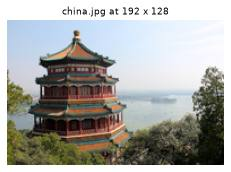

In [ ]:
import io, urllib.request
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/diffusion-models/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}

def load_photo(name):
    """one of the three photos of the course, as a PIL image"""
    data = urllib.request.urlopen(BASE + FILES[name]).read()
    return Image.open(io.BytesIO(data)).convert("RGB")

# Your own photo (optional): remove the # signs, run the cell, choose a file.
# from google.colab import files
# photo = Image.open(next(iter(files.upload()))).convert("RGB")

NAME = "china"          # change to "flower" or "hopper"
photo = load_photo(NAME)
W, H = 192, 128         # we work on a small picture so every cell runs in a second
x0 = np.asarray(photo.resize((W, H), Image.LANCZOS), dtype=float) / 127.5 - 1.0     # pixel 0..255 -> value -1..1
print(NAME, "original size", photo.size, "-> working size", (W, H), " x0 shape (height, width, channels):", x0.shape, " values", round(x0.min(), 2), "to", round(x0.max(), 2))

def show(img, ax, title=""):
    ax.imshow(np.clip((img + 1) / 2, 0, 1)); ax.axis("off"); ax.set_title(title, fontsize=9)

fig, ax = plt.subplots(1, 1, figsize=(4, 2.8)); show(x0, ax, f"{NAME}.jpg at {W} x {H}"); plt.show()

## 2. The forward process: noise a photo with the closed form

`x_t = sqrt(a) * x0 + sqrt(1 - a) * noise`, where `a` is the share of signal left after `t` steps. One line of numpy gives any step at once. We also score how close the picture is to the clean one with PSNR (higher means cleaner). Look at the numbers: they depend on `a`, not on the photo.

t =   50: signal left 0.9710, PSNR of x_t / sqrt(signal) against the clean picture   21.3 dB
t =  150: signal left 0.7883, PSNR of x_t / sqrt(signal) against the clean picture   11.8 dB
t =  300: signal left 0.3964, PSNR of x_t / sqrt(signal) against the clean picture    4.2 dB
t =  500: signal left 0.0786, PSNR of x_t / sqrt(signal) against the clean picture   -4.6 dB
t = 1000: signal left 0.0000, PSNR of x_t / sqrt(signal) against the clean picture  -37.9 dB


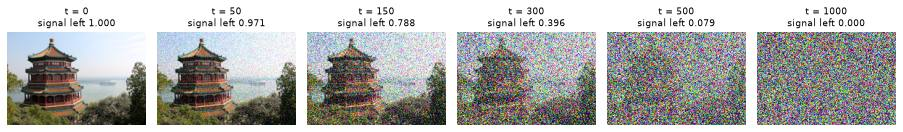

In [ ]:
T = 1000
betas = np.linspace(1e-4, 0.02, T)                      # the linear noise schedule of the lessons
alpha_bar_lin = np.concatenate([[1.0], np.cumprod(1 - betas)])     # index t = signal left after t steps
f = lambda u: np.cos(((u / T + 0.008) / 1.008) * np.pi / 2) ** 2
alpha_bar_cos = np.array([f(t) / f(0) for t in range(T + 1)])      # the cosine schedule

def noised(x0, ab, eps):
    """closed form: jump straight to the step whose cumulative signal is ab"""
    return np.sqrt(ab) * x0 + np.sqrt(1 - ab) * eps

def psnr(a, b):
    """peak signal-to-noise ratio in dB for values in -1..1 (higher = closer to the clean picture)"""
    return 10 * np.log10(4 / np.mean((a - b) ** 2))

eps = np.random.default_rng(5).standard_normal(x0.shape)
steps = [0, 50, 150, 300, 500, 1000]
fig, ax = plt.subplots(1, len(steps), figsize=(13, 2.5))
for a, t in zip(ax, steps):
    show(noised(x0, alpha_bar_lin[t], eps), a, f"t = {t}\nsignal left {alpha_bar_lin[t]:.3f}")
plt.tight_layout(); plt.show()
for t in steps[1:]:
    print(f"t = {t:4d}: signal left {alpha_bar_lin[t]:.4f}, PSNR of x_t / sqrt(signal) against the clean picture {psnr(x0, noised(x0, alpha_bar_lin[t], eps) / np.sqrt(alpha_bar_lin[t])):6.1f} dB")

## 3. One jump or many small steps?

The forward process is defined as many small steps, but the closed form jumps straight to step 300. They should give noise with the same spread (the pictures differ pixel by pixel because the random draws differ).

300 small steps       : mean of the added noise -0.0005, spread 0.7754
one closed-form jump  : mean of the added noise -0.0017, spread 0.7745
formula: spread sqrt(1 - signal left) = 0.7769


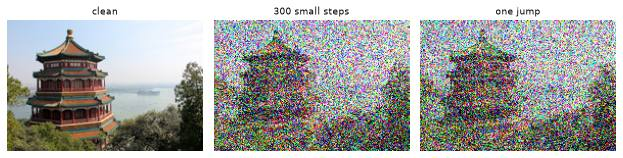

In [ ]:
rng = np.random.default_rng(1)
x = x0.copy()
for i in range(300):                                    # 300 small steps, one loop pass each
    x = np.sqrt(1 - betas[i]) * x + np.sqrt(betas[i]) * rng.standard_normal(x.shape)
one = noised(x0, alpha_bar_lin[300], np.random.default_rng(2).standard_normal(x0.shape))      # one jump
for name, v in [("300 small steps", x), ("one closed-form jump", one)]:
    r = v - np.sqrt(alpha_bar_lin[300]) * x0
    print(f"{name:22s}: mean of the added noise {r.mean():+.4f}, spread {r.std():.4f}")
print(f"formula: spread sqrt(1 - signal left) = {np.sqrt(1 - alpha_bar_lin[300]):.4f}")
fig, ax = plt.subplots(1, 3, figsize=(9, 2.5))
show(x0, ax[0], "clean"); show(x, ax[1], "300 small steps"); show(one, ax[2], "one jump")
plt.tight_layout(); plt.show()

## 4. Linear against cosine schedule

Same photo, same noise, two schedules. The cosine schedule keeps more of the picture in the middle of the run.

step where half the signal is gone: linear 260 cosine 497
steps with less than 1% of the signal left: linear 327 cosine 65


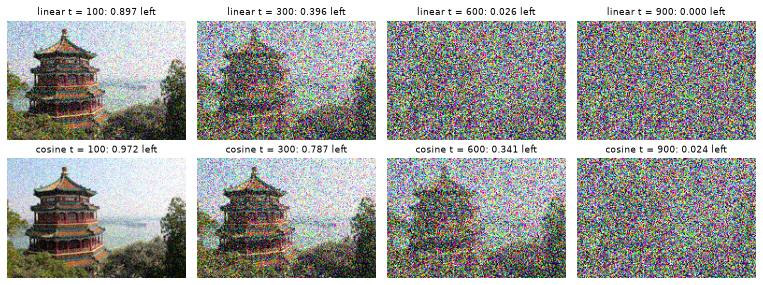

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(11, 4.2))
for j, t in enumerate([100, 300, 600, 900]):
    show(noised(x0, alpha_bar_lin[t], eps), ax[0, j], f"linear t = {t}: {alpha_bar_lin[t]:.3f} left")
    show(noised(x0, alpha_bar_cos[t], eps), ax[1, j], f"cosine t = {t}: {alpha_bar_cos[t]:.3f} left")
plt.tight_layout(); plt.show()
step_half = lambda ab: int(np.argmax(ab < 0.5))
print("step where half the signal is gone: linear", step_half(alpha_bar_lin), "cosine", step_half(alpha_bar_cos))
print("steps with less than 1% of the signal left: linear", int((alpha_bar_lin < 0.01).sum()), "cosine", int((alpha_bar_cos < 0.01).sum()))

## 5. Check against the diffusers library

The library `diffusers` (Hugging Face) is what most people use. Its `DDPMScheduler.add_noise` should produce exactly our closed form. The first run may install the library (about a minute).

In [ ]:
try:
    import torch, diffusers
except ImportError:                                     # Colab has torch but not diffusers
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import torch, diffusers
from diffusers import DDPMScheduler

sched = DDPMScheduler(num_train_timesteps=1000, beta_schedule="linear", beta_start=1e-4, beta_end=0.02)
t = 300
mine = noised(x0, alpha_bar_lin[t], eps)
lib = sched.add_noise(torch.tensor(x0), torch.tensor(eps), torch.tensor([t - 1])).numpy()   # diffusers counts steps from 0: index t-1 = after t steps
print("largest difference between my closed form and diffusers.DDPMScheduler.add_noise:", float(np.abs(mine - lib).max()))

largest difference between my closed form and diffusers.DDPMScheduler.add_noise: 1.8779500043919484e-07


## 6. The reverse side: a best guess of the clean photo

A denoiser guesses the clean picture from a noisy one. We start with the simplest model: every colour channel is one bell curve. The guess shrinks the noisy value towards the average, more strongly when there is more noise.

  t   rescaled x_t (dB)   best guess (dB)
  20           28.4              28.5
 100           15.4              16.5
 300            4.2              10.8
 600           -9.7               9.7


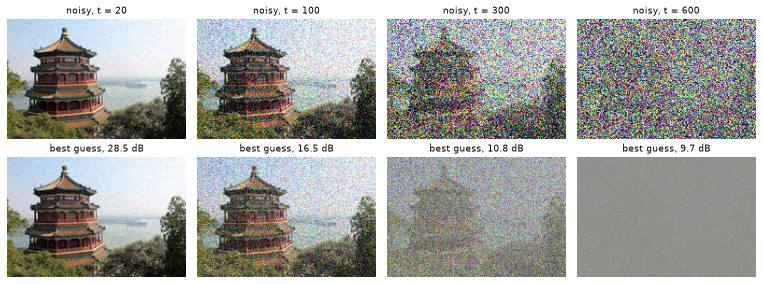

In [ ]:
# The simplest denoiser: assume every colour channel is one bell curve (mean m, variance s) and take the best guess under that model.
def gauss_guess(xt, ab):
    out = np.empty_like(xt)
    for c in range(3):
        m, s = x0[..., c].mean(), x0[..., c].var()
        out[..., c] = m + np.sqrt(ab) * s / (ab * s + 1 - ab) * (xt[..., c] - np.sqrt(ab) * m)
    return out

fig, ax = plt.subplots(2, 4, figsize=(11, 4.2))
print("  t   rescaled x_t (dB)   best guess (dB)")
for j, t in enumerate([20, 100, 300, 600]):
    xt = noised(x0, alpha_bar_lin[t], eps)
    g = gauss_guess(xt, alpha_bar_lin[t])
    r = xt / np.sqrt(alpha_bar_lin[t])
    show(xt, ax[0, j], f"noisy, t = {t}"); show(g, ax[1, j], f"best guess, {psnr(x0, g):.1f} dB")
    print(f"{t:4d}   {psnr(x0, r):12.1f}   {psnr(x0, g):15.1f}")
plt.tight_layout(); plt.show()

## 7. A better model: the typical spectrum of photographs

Photographs have lots of energy in large smooth shapes and little in fine grain. A denoiser that knows this keeps the smooth part and removes the grain. We measure the typical spectrum on the two other photos and apply it to this one.

  t   one bell curve (dB)   typical photo spectrum (dB)
  20                28.5                       30.0
 100                16.5                       22.4
 300                10.8                       18.6
 600                 9.7                       14.9


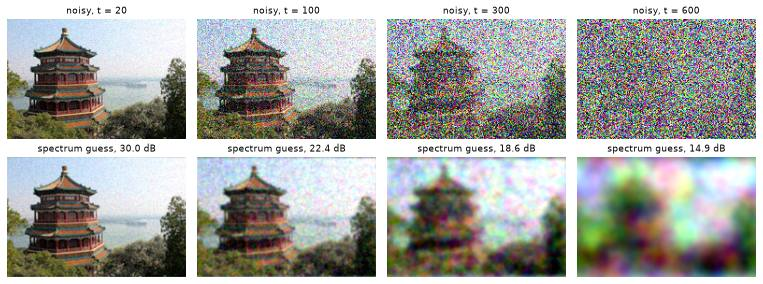

In [ ]:
# A better model: photographs have a typical amount of energy at each level of detail (smooth shapes strong, grain weak).
# We measure it on the OTHER two photos and use it as the model for the noisy picture.
def power(img):
    return sum(np.abs(np.fft.fft2(img[..., c])) ** 2 / img[..., 0].size for c in range(3)) / 3

fy, fx = np.fft.fftfreq(H)[:, None], np.fft.fftfreq(W)[None, :]
radius = np.sqrt(fy ** 2 + fx ** 2)
bins = np.linspace(0, radius.max() + 1e-9, 41)
which = np.digitize(radius, bins).clip(1, 40) - 1
others = [n for n in FILES if n != NAME]
curve = np.zeros(40)
for n in others:
    p = np.asarray(load_photo(n).resize((W, H), Image.LANCZOS), dtype=float) / 127.5 - 1.0
    pw = power(p)
    curve += np.array([pw[which == b].mean() for b in range(40)]) / len(others)
S = curve[which]                                        # model power at every frequency of our picture

def spectral_guess(xt, ab):
    gain = np.sqrt(ab) * S / (ab * S + (1 - ab))
    return np.stack([np.real(np.fft.ifft2(np.fft.fft2(xt[..., c]) * gain)) for c in range(3)], axis=-1)

fig, ax = plt.subplots(2, 4, figsize=(11, 4.2))
print("  t   one bell curve (dB)   typical photo spectrum (dB)")
for j, t in enumerate([20, 100, 300, 600]):
    xt = noised(x0, alpha_bar_lin[t], eps)
    g = spectral_guess(xt, alpha_bar_lin[t])
    show(xt, ax[0, j], f"noisy, t = {t}"); show(g, ax[1, j], f"spectrum guess, {psnr(x0, g):.1f} dB")
    print(f"{t:4d}   {psnr(x0, gauss_guess(xt, alpha_bar_lin[t])):17.1f}   {psnr(x0, g):24.1f}")
plt.tight_layout(); plt.show()

## 8. Generation from pure noise

Now the sampling loop: start from noise, guess the clean picture, step a little towards it, repeat. With the spectrum denoiser the samples are smooth, cloud-like patterns with strongly saturated colours: the amount of large and fine detail is photo-like, but there are no objects and the colours are wrong (the model ignores that photo colours are linked and have an average). That gap is what a trained neural network closes.

The samples have a photo-like mix of large and fine detail, but no objects and wrong colours: this simple model knows only how much energy each level of detail has.
A neural network trained on many photographs knows what objects look like. The training loop is the next topic.


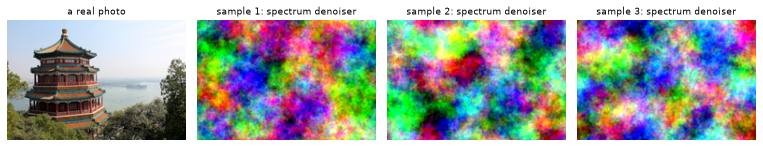

In [ ]:
# Generation = start from pure noise and walk back with the denoiser (DDIM steps, 50 of the 1000).
def sample(guess, seed, n_steps=50):
    r = np.random.default_rng(seed)
    x = r.standard_normal(x0.shape)
    ts = np.linspace(1000, 1, n_steps).round().astype(int)
    for k, t in enumerate(ts):
        ab = alpha_bar_lin[t]
        x0_hat = guess(x, ab)
        e_hat = (x - np.sqrt(ab) * x0_hat) / np.sqrt(1 - ab)
        ab_next = alpha_bar_lin[ts[k + 1]] if k + 1 < len(ts) else 1.0
        x = np.sqrt(ab_next) * x0_hat + np.sqrt(1 - ab_next) * e_hat
    return x

fig, ax = plt.subplots(1, 4, figsize=(11, 2.4))
show(x0, ax[0], "a real photo")
for j, sd in enumerate([1, 2, 3]):
    show(sample(spectral_guess, sd), ax[j + 1], f"sample {j + 1}: spectrum denoiser")
plt.tight_layout(); plt.show()
print("The samples have a photo-like mix of large and fine detail, but no objects and wrong colours: this simple model knows only how much energy each level of detail has.")
print("A neural network trained on many photographs knows what objects look like. The training loop is the next topic.")

## Try it yourself

1. Set `NAME = "flower"` or `"hopper"` in the first code cell and run everything again. Which numbers change? Which stay the same (look at the PSNR column of section 2)?
2. In section 2 change `steps` to `[0, 10, 20, 40, 80, 160]`. At which step can you first see grain?
3. Use your own photo (first cell). Does the PSNR at t = 300 change? Why should it not (the noise only depends on the signal left)?
4. In section 6 change the number of sampling steps from 50 to 10 and to 200. Does the sample change much?
5. In your own words: why is the best guess blurrier at t = 600 than at t = 20? Write one sentence for a colleague who has not seen diffusion.